# Numerical Error

## Part A — Theory and Numerical Methods

**In this part we develop the mathematical ideas behind floating-point error, error accumulation, and three-term recurrence relations. We then derive the upward and downward recurrence strategies for spherical Bessel functions, including the motivation for Miller's algorithm.**

**By the end of Part A, you should be able to identify when a recurrence is numerically unstable and explain why reversing its direction can improve the result.**


Arithmetic with **floating-point** numbers is not exact, so numerical error can accumulate during an iteration.

A binary floating-point number is stored approximately as
$\text{sign} \times \text{significand}\times 2^ {\text{exponent}}$. A Python `float` uses the IEEE-754 binary64 format: 1 sign bit, 11 exponent bits, and 52 explicitly stored significand bits (53 bits of precision including the hidden leading bit). Its machine precision is
$$\varepsilon_{\mathrm{mach}} = 2^{-52} \approx 2.22\times 10^{-16}.$$


Most often we will use this python `float`, which can store numbers between $2.22507 \;e^{-308 }$ to $1.79769 \; e^ {+308}$.

 The overflow error occurs if we want to store $x > 1.79769\; 10^{308}$ and underflow when
$x < 2.22507\; 10^{−308}$. These numbers are sufficiently large/small that usually do not cause problems. 
If they do, we should probably work with logarithms of the numbers (`log` representation).

The **roundoff error** is the hardest problem to avoid, which occurs when : $1+\epsilon == 1$. For 64-bit `float` it occurs around (only!) $2 10^{−16}$.

This is a scale for **roundoff**, not an absolute error bound for every calculation. Each elementary operation is rounded to a nearby representable number, and repeated operations can amplify those small perturbations. Overflow and underflow are different phenomena: they occur when a result is outside the representable range. In this notebook the important issue is roundoff amplification inside a recurrence.


In [1]:
for i in range(1,10):
    x= 1 + i *  1e-17
    print('1 + '+str(i)+' e -16 -1 = ', x)

1 + 1 e -16 -1 =  1.0
1 + 2 e -16 -1 =  1.0
1 + 3 e -16 -1 =  1.0
1 + 4 e -16 -1 =  1.0
1 + 5 e -16 -1 =  1.0
1 + 6 e -16 -1 =  1.0
1 + 7 e -16 -1 =  1.0
1 + 8 e -16 -1 =  1.0
1 + 9 e -16 -1 =  1.0


In [ ]:
for i in range(1,10):
    x= 1 + i *  1e-16 -1
    print('1 + '+str(i)+' e -16 -1 = ', x)


1 + 1 e -16 -1 =  0.0
1 + 2 e -16 -1 =  2.220446049250313e-16
1 + 3 e -16 -1 =  2.220446049250313e-16
1 + 4 e -16 -1 =  4.440892098500626e-16
1 + 5 e -16 -1 =  4.440892098500626e-16
1 + 6 e -16 -1 =  6.661338147750939e-16
1 + 7 e -16 -1 =  6.661338147750939e-16
1 + 8 e -16 -1 =  8.881784197001252e-16
1 + 9 e -16 -1 =  8.881784197001252e-16


Many numerical methods rely on iterations. A small error introduced at one step becomes part of the data used at the next step, so the iteration can either damp the error or amplify it.

### Let's take, for example: 

A three-term linear recurrence has the form
$$x_{n+1}=a_nx_n+b_nx_{n-1}.$$

It is a discrete analogue of a second-order differential equation and appears in algorithms for Bessel, Legendre, and related special functions. For constant coefficients, try $x_n=r^n$. The characteristic equation is
$$r^2-ar-b=0,$$
with roots
$$r_{1,2}=\frac{a\pm\sqrt{a^2+4b}}{2}.$$
Thus the general solution is
$$x_n=C_1r_1^n+C_2r_2^n.$$
If the root is repeated, the two independent solutions are $r^n$ and $nr^n$.

The key numerical distinction is between a **dominant** solution, whose magnitude grows faster in the chosen direction, and a **minimal** solution, whose magnitude is relatively smaller. A computed value almost never contains only the desired solution: roundoff introduces a tiny amount of the other independent solution. If the unwanted solution is dominant in the direction of iteration, that tiny component eventually overwhelms the desired one. The recurrence may still satisfy its equation accurately while producing the wrong solution.

A three-term recurrence has two linearly independent solutions. For spherical Bessel functions these are $j_l(x)$ and the spherical Neumann function $y_l(x)$. When $x$ is small compared with $l$, $j_l(x)$ is minimal and $y_l(x)$ is dominant. Therefore upward recurrence is unstable for $j_l$ in that regime: roundoff contamination by $y_l$ grows rapidly. Reversing the recurrence makes the unwanted component minimal, so downward recurrence is stable for $j_l$.

This is the central lesson illustrated by John D. Cook's example: **stability belongs to a direction and a particular solution, not to the recurrence formula alone**. The same recurrence can be stable upward for one solution and downward for the other. Miller's algorithm exploits a stable downward direction by starting at a sufficiently large order with arbitrary values and then fixing the unknown overall scale using a normalization condition.


## Spherical Bessel functions

The spherical Bessel functions satisfy the three-term recurrence
$$j_{l+1}(x)=\frac{2l+1}{x}j_l(x)-j_{l-1}(x),$$
with starting values
$$j_0(x)=\frac{\sin x}{x},\qquad
j_1(x)=\frac{\sin x}{x^2}-\frac{\cos x}{x}.$$

The same recurrence is satisfied by the spherical Neumann functions $y_l(x)$, which form the second independent solution. Near $x=0$, $j_l(x)\sim x^l$ is very small while $y_l(x)\sim x^{-(l+1)}$ is large. This separation explains the numerical behavior: when $x\ll l$, upward recurrence for $j_l$ can acquire a tiny $y_l$ component and then magnify it. Downward recurrence suppresses that contamination instead.

Consequently, the recurrence is not automatically stable just because it is algebraically exact. We must choose its direction based on the solution we want and on the relative sizes of the independent solutions. The experiments below compare the computed values with `scipy.special.spherical_jn` so that this distinction is visible.


To refresh our memory, spherical Bessel functions are solutions of the radial Schroedinger equation, as well as the Electromagnetic waves in a cylindrical symmetry, 
heat conduction in a cylindrical object, 
and many other applications.

They are the solution of the following differential equation:

$$\left[-\frac{1}{2}\frac{d^2}{dr^2}+\frac{l(l+1)}{2 r^2}\right]\left(r j_l(r)\right) = E \left(r j_l(r)\right)$$

Starting from $j_0$ and $j_1$ and increasing $l$ is called **upward recurrence**. It is convenient and works well when the desired solution is dominant or when $l$ is not too large compared with $x$. For small $x$ and increasing $l$, however, $j_l$ is the minimal solution and the upward iteration is unstable: the unwanted Neumann solution grows relative to it. The recurrence can therefore produce values with a large relative error even though every step uses the exact recurrence formula.

## Part B — Guided Implementation

The following short examples translate the ideas from Part A into Python. Run the cells, inspect the numerical errors, and use the implementations as models for writing your own recurrence routines.


### NOTE: Reading errors in the numerical experiment

For a fixed small argument, inspect the relative error rather than only the printed decimal values. A value such as $10^{-20}$ can have a tiny absolute error but a completely unacceptable relative error. In the language of stable recurrences, upward iteration is following the dominant contamination instead of the desired minimal solution. This is why the article's Bessel example finds upward recurrence accurate for the second-kind solution but unstable for the first-kind solution, while reversing the direction swaps those conclusions. Our spherical-Bessel experiment has the same structure.

### Upward recurrence

We evaluate the upward recurrence using
$$j_{l+1}(x)=\frac{2l+1}{x}j_l(x)-j_{l-1}(x).$$

The next cell will make the mechanism concrete. It is analogous to the numerical experiment in [John D. Cook's discussion of stable recurrence relations](https://www.johndcook.com/blog/2020/01/17/stable-recurrence-relations/): the same three-term structure can be accurate in one direction and disastrously inaccurate in the other, depending on which independent solution is being followed.

In [10]:
from scipy import *
from numpy import *

def bessel_upward(l,x):
    "returns array of j_i from i=0 to i=l, including l"
    res = zeros(l+1)
    if abs(x)<1e-30: # first take care of the special case, which is numerically hard.
        res[0]=1.
        return res
    j0 = sin(x)/x
    res[0]=j0
    if l==0: return res
    j1 = j0/x - cos(x)/x
    res[1] = j1
    
    for i in range(1,l):
        j2 = (2*i+1)/x*j1 - j0  # (j2,j1,j0)==(j_{i+1},j_i,j_{i-1})
        res[i+1]=j2             # store j_{i+1}
        j0,j1 = j1,j2           # prepare for the next step (j_{i-1},j_i) <- (j_i,j_{i+1})
    return res

In [11]:
from scipy import special

l=10
x=0.1

dat0 = bessel_upward(l,x)
dat1 = special.spherical_jn(range(l+1),x)

diff = dat0-dat1

print("%4s %16s %16s %16s %16s" % ('l','exact','upward','abs-error','rel-error'))
for i in range(len(dat0)):
    print("%4d %16.13f %16.13f %16.13f %16.8g" % (i,dat1[i],dat0[i],diff[i], diff[i]/dat1[i]))

   l            exact           upward        abs-error        rel-error
   0  0.9983341664683  0.9983341664683  0.0000000000000                0
   1  0.0333000119026  0.0333000119026  0.0000000000000    3.7507521e-15
   2  0.0006661906084  0.0006661906084  0.0000000000000    6.4359747e-12
   3  0.0000095185197  0.0000095185199  0.0000000000002    2.2510964e-08
   4  0.0000001057720  0.0000001057870  0.0000000000150    0.00014176421
   5  0.0000000009616  0.0000000023109  0.0000000013493        1.4031448
   6  0.0000000000074  0.0000001484162  0.0000001484088        20061.914
   7  0.0000000000000  0.0000192917991  0.0000192917990    3.9116462e+08
   8  0.0000000000000  0.0028936214469  0.0028936214469    9.9738775e+12
   9  0.0000000000000  0.4918963541799  0.4918963541799    3.2213554e+17
  10  0.0000000000000 93.4574136727252 93.4574136727252    1.2852544e+22


In [9]:
x=0.1
j9  = special.spherical_jn(9,x)
j10 = special.spherical_jn(10,x)
j11 = special.spherical_jn(11,x)

j11a = (2*10+1)/x * j10 - j9  # upward
j9a = (2*10+1)/x * j10 - j11  # downward
print('part1 upward or downward=', (2*10+1)/x*j10)
print('part2 upward=', -j9)
print('part2 downward=', -j11)

print('j9=', j9a, 'j9_exact=', j9, 'abs-err=', j9a-j9, 'rel-err=', (j9a-j9)/j9)
print('j11=', j11a, 'j11_exact=',j11, 'abs-err=', j11a-j11, 'rel-err=', (j11a-j11)/j11)

part1 upward or downward= 1.5270173093098784e-18
part2 upward= -1.5269856934948229e-18
part2 downward= -3.16158150515107e-23
j9= 1.526985693494827e-18 j9_exact= 1.5269856934948229e-18 abs-err= 4.044452883213195e-33 rel-err= 2.648651457864433e-15
j11= 3.161581505555956e-23 j11_exact= 3.16158150515107e-23 abs-err= 4.048855109557025e-33 rel-err= 1.280642331364966e-10


The table above should show the characteristic failure of upward recurrence when $x$ is small compared with $l$: the absolute error may initially look small, but the relative error grows rapidly because $j_l(x)$ itself becomes tiny. This is not merely “error accumulation” in the vague sense. Roundoff has introduced a small component of the second solution $y_l$, and upward recurrence amplifies that component. Downward recurrence reverses the roles and recovers the minimal solution accurately.

### Downward recurrence: Miller's algorithm


Rearrange the same relation to step toward smaller orders:
$$j_{l-1}(x)=\frac{2l+1}{x}j_l(x)-j_{l+1}(x).$$

For $x\ll l$, this direction is stable for the minimal solution $j_l$. We do not know the true starting values at a large order, so Miller's algorithm starts with convenient values, for example $\tilde j_{L+1}=0$ and $\tilde j_L=1$, and recurses downward. Because the recurrence is linear and homogeneous, all computed values differ from the desired sequence by one common multiplicative factor:
$$\tilde j_l=Cj_l.$$

The factor $C$ is removed using a known normalization, here $j_0(x)=\sin(x)/x$. Thus downward recurrence supplies the **shape** of the solution, while the normalization supplies its scale. The starting order $L$ must be sufficiently larger than the largest requested order so that the arbitrary starting values have been damped before the desired values are read out.

In [5]:
def bessel_downward(l,x):
    "downward recursion"
    if abs(x)<1e-20:   # again take care of the special case where the algorithm would be unstable.
        res = zeros(l+1)
        res[0]=1
        return res
    lstart = l + int(sqrt(10*l)) # this is a reasonable l_max
    j2 = 0.
    j1 = 1.
    res = [] # [j_l,j_{l-1},.....j_0]
    for i in range(lstart,0,-1):
        j0 = (2*i+1)/x * j1 - j2
        if i-1<=l : res.append(j0)
        j2,j1 = j1,j0
    res.reverse()      # reverse the list: [j0,j1,....j_l]
    true_j0 = sin(x)/x
    res = array(res) * true_j0/res[0]
    return res

In [12]:
l=10
x=0.1
dat0 = bessel_downward(l,x)
dat1 = special.spherical_jn(range(l+1),x)
diff=dat0-dat1

print("%4s %16s %16s %16s %16s" % ('l','exact','downward','abs-error','rel-error'))
for i in range(len(dat0)):
    print("%4d %16.13f %16.13f %16.13f %16.8g" % (i,dat1[i],dat0[i],diff[i], diff[i]/dat1[i]))

   l            exact         downward        abs-error        rel-error
   0  0.9983341664683  0.9983341664683  0.0000000000000                0
   1  0.0333000119026  0.0333000119026 -0.0000000000000   -6.2512535e-16
   2  0.0006661906084  0.0006661906084 -0.0000000000000   -9.7647925e-16
   3  0.0000095185197  0.0000095185197 -0.0000000000000   -1.4238062e-15
   4  0.0000001057720  0.0000001057720  0.0000000000000    6.2563287e-16
   5  0.0000000009616  0.0000000009616 -0.0000000000000   -2.1504626e-16
   6  0.0000000000074  0.0000000000074  0.0000000000000    8.7358062e-16
   7  0.0000000000000  0.0000000000000 -0.0000000000000   -1.6634916e-15
   8  0.0000000000000  0.0000000000000 -0.0000000000000   -1.1895996e-15
   9  0.0000000000000  0.0000000000000 -0.0000000000000   -1.8918939e-15
  10  0.0000000000000  0.0000000000000 -0.0000000000000   -4.5522754e-15


In [ ]:
def bessel_j(l,x):
    "combines upward and downward recursion"
    if l<=x : return bessel_upward(l,x)
    # If x is largel we only need upward recursion. However, when x is small, we need both the
    # upward and downward. The upward for l<x and downward for l>x.
    lcritical = int(x)
    if lcritical<=0 : return bessel_downward(l,x)  # for very small x we only need downward recursion
    
    _ju_ = bessel_upward(lcritical-1,x)             # upward works
    _jd_ = bessel_downward(l,x)
    return hstack( (_ju_, _jd_[lcritical:]) )

In [ ]:
l=10
x=0.1
dat0 = bessel_upward(l,x)
dat1 = bessel_downward(l,x)
dat2 = bessel_j(l,x)
date = special.spherical_jn(range(l+1),x)
diff = date-dat2
#print('difference=', date-dat2)
#print('updard-diff=', date-dat0)
#print('down-diff=', date-dat1)


print("%4s %16s %16s %16s %16s" % ('l','exact','combined','abs-error','rel-error'))
for i in range(len(dat0)):
    print("%4d %16.13f %16.13f %16.13f %16.8g" % (i, date[i], dat2[i], diff[i], diff[i]/date[i]))

   l            exact         combined        abs-error        rel-error
   0  0.9983341664683  0.9983341664683  0.0000000000000                0
   1  0.0333000119026  0.0333000119026  0.0000000000000    6.2512535e-16
   2  0.0006661906084  0.0006661906084  0.0000000000000    9.7647925e-16
   3  0.0000095185197  0.0000095185197  0.0000000000000    1.4238062e-15
   4  0.0000001057720  0.0000001057720 -0.0000000000000   -6.2563287e-16
   5  0.0000000009616  0.0000000009616  0.0000000000000    2.1504626e-16
   6  0.0000000000074  0.0000000000074 -0.0000000000000   -8.7358062e-16
   7  0.0000000000000  0.0000000000000  0.0000000000000    1.6634916e-15
   8  0.0000000000000  0.0000000000000  0.0000000000000    1.1895996e-15
   9  0.0000000000000  0.0000000000000  0.0000000000000    1.8918939e-15
  10  0.0000000000000  0.0000000000000  0.0000000000000    4.5522754e-15


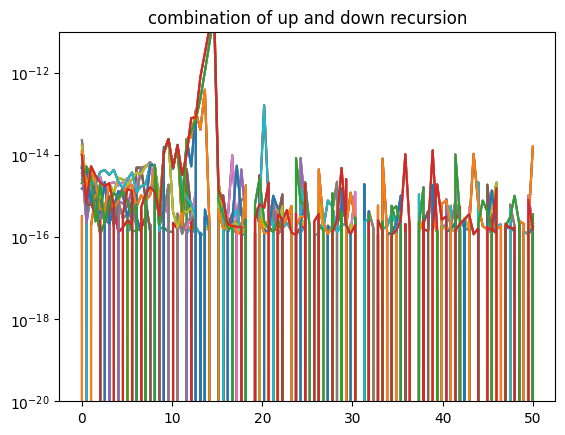

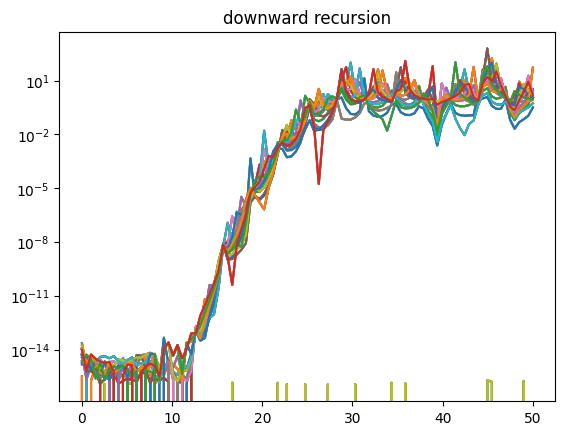

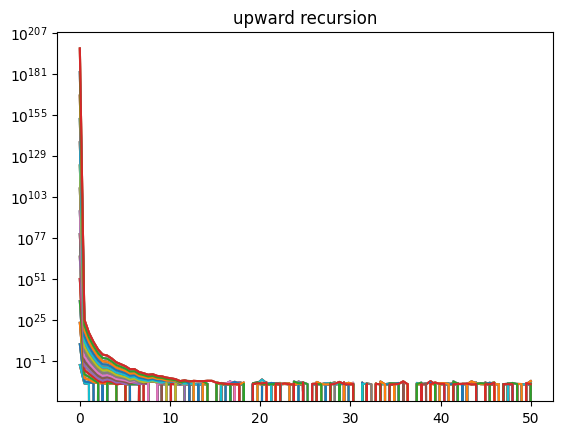

In [ ]:
from pylab import *
%matplotlib inline

l=15
x = linspace(1e-6,50,100)
dat0 = array([bessel_upward(l,t) for t in x])
dat1 = array([bessel_downward(l,t) for t in x])
dat2 = array([bessel_j(l,t) for t in x])
date = array([special.spherical_jn(range(l+1),t) for t in x])

for i in range(5,l,3):
    semilogy(x, abs((dat2-date)/date))
title('combination of up and down recursion')
ylim([1e-20,1e-11])

show()

for i in range(5,l,3):
    semilogy(x, abs((dat1-date)/date))
title('downward recursion')
show()

for i in range(5,l,3):
    semilogy(x, abs((dat0-date)/date))
title('upward recursion')
show()


## Part C — Exercises

Use these activities to consolidate the theory and practice the implementation before attempting the computational problem.

1. **Conceptual questions:** Explain why the upward recurrence is unreliable when $x$ is small compared with $l$. Which solution of the recurrence contaminates the computed result?
2. **Code reading:** Identify the two starting values and the loop invariant in `bessel_upward`. Add a check that the returned array has length `l + 1`.
3. **Partially completed code:** Modify `bessel_downward` so that it reports the maximum absolute and relative error against `scipy.special.spherical_jn` for a chosen pair $(l,x)$.
4. **Independent programming task:** For several values of $x$ and $l$, compare upward, downward, and combined recurrence. Create a small table or plot showing where each method is accurate.

Record the reasoning behind your conclusions, not only the numerical output. Ask the instructor if a result appears to contradict the stability analysis.


## Part D — Computational Problems

**Pair work:** Work in pairs to develop, implement, and analyze a solution. Your completed notebook or report will be submitted as part of the course exercise sheet.

We want to compute the series of integrals, defined by
$$K_n(z,\alpha) = \int_0^1 dx \frac{x^n}{z+\alpha x}$$
when $n=0,1,...n_{max}=10$.

These occur, for example, when we evaluate matrix elements of the following correlation function $$ <P_n(x)|G_(x)|P_m(x)>, $$ where $P_n(x)$ is Legendre polynomial, and $ G(x)=\frac{1}{z-x} $ is the Green's function.

We can derive recurrence relation by noting
$$K_{n+1}(z,\alpha) = \int_0^1 dx \frac{x^n(x+z/\alpha) -  x^n z/\alpha}{z+\alpha x}=
\frac{1}{\alpha} \int_0^1 dx x^n -\frac{z}{\alpha}\int_0^1 dx  \frac{x^n}{z+\alpha x}$$
which gives
$$K_{n+1} = \frac{1}{\alpha(n+1)}-\frac{z}{\alpha} K_n$$

We can also calculate $K_0$:
$$K_0=\frac{1}{\alpha} \log(1+\alpha/z)$$

- Starting for $K_0$ you can compute $K_n$ up to $n_{max}$ using recurrence. This works quite well for $|\alpha/z|\gtrapprox 1$.

- Choosing $z$ and $\alpha$ so that $|\alpha/z|\ll 1$ (for example $\alpha/z=10^{-4}$) verify that upward recurrence is unstable.

- Implement downward recurrence for $\alpha/z<1/2$. Since recurrence relation is not homogeneous, we can not start with arbitrary value and later normalize result. We thus need to start with very accurate value of $K_{n_{max}}$. 
Use power series expansion for $K_{n_{max}}$ in powers of $(\alpha/z)^k$, and evaluate as many terms as needed to achieve desired accuracy (say $10^{-12}$).

We can derive the power series in $\alpha/z$ by Taylor expansion:
$$K_n(z,\alpha) = \frac{1}{z}\int_0^1 dx \frac{x^n}{1+\alpha/z x}=
\frac{1}{z} \sum_{k=0}^{\infty}(-\alpha/z)^k \int_0^1 dx x^{n+k}=
\frac{1}{z} \sum_{k=0}^{\infty}\frac{(-\alpha/z)^k}{n+k+1}$$
For $n$ large and $|\alpha/z|<1/2$ this series is is converging well.

The first order recurrence relation can be solved analytically by the algorithm described in <a href="https://en.wikipedia.org/wiki/Recurrence_relation">wikipedia:Recurrence relation</a>

The solution is:

$$K_n = \left(-\frac{z}{\alpha}\right)^n\left[K_0 + \frac{1}{\alpha}\sum_{k=1}^{n} \frac{\left(-\frac{\alpha}{z}\right)^k}{k}\right]$$

By noting that Taylor expansion of $\log(1+x)=-\sum_{k=1}^{\infty} \frac{(-x)^k}{k}$, we see that 
$$K_0=-\frac{1}{\alpha}\sum_{k=1}^\infty \frac{\left(-\frac{\alpha}{z}\right)^k}{k}$$
and inserting this expression into previous formula for $K_n$ gives Taylor expansion that we derived for small $\alpha/z$ above.


You can use this expression to check your implementation of recurrence relation.